# Retrieval evaluation — Knowledge Base v2

**Medical Chatbot Simulation | Development analysis**

This notebook examines the retrieval baseline for a multilingual RAG prototype. It uses the outputs of the tested evaluation scripts rather than recomputing embeddings or implementing metrics a second time.

The knowledge base contains **15 documents and 54 section-based chunks**. Queries are primarily in Spanish; source documents are in English. Retrieval uses `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2` with cosine similarity.

**Evaluation protocol:** The 60-query **development** split supports analysis and configuration decisions. The separate 60-query **test** split remains held out until the retrieval configuration is frozen. No test predictions or metrics are loaded here.

> **Scope:** This is an educational evaluation of retrieval, not of generated-answer correctness or clinical safety. The knowledge base includes fictional clinic policies.

## Analysis roadmap

1. **Setup and data integrity** — load the saved development reports and check consistency.
2. **Ranking performance** — compare Hit@1, Recall@k, Complete Evidence@k, and MRR across query types.
3. **Similarity score distributions** — compare answerable, in-domain unsupported, and out-of-domain questions.
4. **Retrieve-or-reject analysis** — examine sensitivity, specificity, confusion matrices, and unsupported-query failure modes.
5. **Qualitative error analysis** — inspect ranking failures and semantically related but insufficient evidence.
6. **Development conclusions** — make provisional, documented decisions and specify the held-out test protocol.

**Scope:** This notebook uses **development data only**. No training or fine-tuning takes place; the retriever is a pretrained embedding model applied to a fixed KB. The existing Python modules generate the metrics and results. This notebook visualizes and interprets their saved outputs.


## 1. Setup and data integrity

All three reports were generated by existing Python modules in `evaluation/`:

- `run_retrieval_benchmark.py` → ranked chunks and cosine similarity scores;
- `summarize_retrieval_results.py` → answerable-query ranking metrics;
- `evaluate_retrieval_threshold.py` → acceptance/rejection metrics.

We load the saved JSON reports to keep the analysis lightweight and reproducible. Paths work when Jupyter is started from either the repository root or the `evaluation/` directory.

In [1]:
import json
from pathlib import Path

import pandas as pd

# Support running Jupyter from the repository root or evaluation/.
working_dir = Path.cwd()
candidates = [working_dir / "evaluation", working_dir]

evaluation_dir = next(
    (
        path
        for path in candidates
        if (path / "retrieval_results_dev_v2.json").is_file()
    ),
    None,
)

if evaluation_dir is None:
    raise FileNotFoundError(
        "Could not locate development results. Start Jupyter from "
        "the repository root or its evaluation/ directory."
    )


def load_json(filename: str) -> dict:
    with (evaluation_dir / filename).open(encoding="utf-8") as file:
        return json.load(file)


retrieval_data = load_json("retrieval_results_dev_v2.json")
summary_data = load_json("retrieval_summary_dev_v2.json")
threshold_data = load_json("retrieval_threshold_dev_v2.json")

print(f"Evaluation directory: {evaluation_dir}")
print(f"Model: {retrieval_data['model_name']}")
print(f"Dataset: {retrieval_data['dataset']}")
print(f"Top-k saved: {retrieval_data['top_k']}")

Evaluation directory: /home/usuario/Documentos/Proyectos/medical_chatbot_sim/evaluation
Model: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Dataset: retrieval_dataset_dev_v2.json
Top-k saved: 5


### 1.1 Cross-check the saved reports

These checks catch stale or mismatched files (for example, a summary generated from a different dataset). They are intentionally lightweight; formal metric tests remain in `tests/`.

In [2]:
results = retrieval_data["results"]
query_ids = [item["query_id"] for item in results]
n_answerable = sum(item["answerable"] for item in results)

assert (
    retrieval_data["dataset"]
    == summary_data["dataset"]
    == threshold_data["dataset"]
    == "retrieval_dataset_dev_v2.json"
)
assert len(results) == summary_data["n_queries"] == threshold_data["n_queries"] == 60
assert len(query_ids) == len(set(query_ids))
assert n_answerable == summary_data["n_answerable"] == 45
assert len(results) - n_answerable == summary_data["n_unsupported"] == 15
assert all(len(item["retrieved_chunks"]) == retrieval_data["top_k"] for item in results)

print("Report consistency checks passed.")

Report consistency checks passed.


### 1.2 Build a query-level analysis table

The table has **one row per query**. We retain the question category, its answerability label, the Top-1 score, and the IDs of the retrieved and gold evidence. This makes later plots and error analysis easier without changing the stored benchmark format.

**Important:** `top1_score` measures semantic similarity; it is **not** a calibrated probability that the question is answerable.

In [3]:
queries_df = pd.DataFrame(
    [
        {
            "query_id": item["query_id"],
            "query": item["query"],
            "category": item["category"],
            "answerable": item["answerable"],
            "top1_score": item["retrieved_chunks"][0]["score"],
            "top1_chunk_id": item["retrieved_chunks"][0]["chunk_id"],
            "relevant_ids": item["relevant_chunk_ids"],
            "retrieved_ids": [
                chunk["chunk_id"] for chunk in item["retrieved_chunks"]
            ],
        }
        for item in results
    ]
)

queries_df.head()

,query_id,query,category,answerable,top1_score,top1_chunk_id,relevant_ids,retrieved_ids
0,q_001,¿Tener 37 grados de temperatura significa que ...,single_evidence,True,0.814020,medlineplus_fever_000,[medlineplus_fever_000],"[medlineplus_fever_000, medlineplus_common_col..."
1,q_002,¿Qué síntomas pueden indicar una deshidratació...,single_evidence,True,0.792024,medlineplus_dehydration_002,[medlineplus_dehydration_002],"[medlineplus_dehydration_002, medlineplus_diar..."
2,q_003,¿Tengo que estar en ayunas para hacerme un hem...,single_evidence,True,0.365381,medlineplus_complete_blood_count_002,[medlineplus_complete_blood_count_002],"[medlineplus_complete_blood_count_002, medline..."
3,q_004,¿Qué es la anafilaxia y qué tipo de atención r...,single_evidence,True,0.364817,medlineplus_allergy_001,[medlineplus_allergy_001],"[medlineplus_allergy_001, medlineplus_allergy_..."
4,q_005,¿Qué personas tienen mayor riesgo de desarroll...,single_evidence,True,0.734271,medlineplus_rsv_003,[medlineplus_rsv_001],"[medlineplus_rsv_003, medlineplus_rsv_000, med..."


### 1.3 Check the question distribution

The benchmark is intentionally balanced by question type rather than sampled from actual patient traffic. Ranking metrics will be computed only on answerable queries; unsupported queries will be studied separately for retrieve-or-reject behavior.

In [4]:
category_order = [
    "single_evidence",
    "multi_evidence",
    "in_domain_unsupported",
    "out_of_domain",
]

category_counts = (
    queries_df["category"]
    .value_counts()
    .reindex(category_order, fill_value=0)
    .rename_axis("category")
    .reset_index(name="n_queries")
)

assert category_counts["n_queries"].tolist() == [35, 10, 8, 7]

category_counts

,category,n_queries
0,single_evidence,35
1,multi_evidence,10
2,in_domain_unsupported,8
3,out_of_domain,7


**Initial observation.** Development contains **45 answerable** and **15 unsupported** queries. These category quotas are fixed by design. As a result, any aggregate rate reflects this educational benchmark's mixture, not the prevalence of query types in actual use.

**Next:** analyze ranking quality on the 45 answerable questions, particularly whether Top-3 retrieves all required evidence for multi-evidence queries.

## 2. Ranking performance

**Question:** Does retrieving more chunks improve evidence coverage, and is the effect different for single- and multi-evidence questions?

This section evaluates *ranking* independently of the similarity threshold. Metrics come from `retrieval_summary_dev_v2.json` and are calculated only for the 45 **answerable** development queries.

- **Hit@1:** whether the first retrieved chunk is relevant.
- **Recall@k:** fraction of the annotated evidence set found among the first `k` chunks, averaged over queries.
- **Complete Evidence@k:** fraction of queries for which **every** annotated chunk is present among the first `k` results.
- **MRR@5:** mean reciprocal rank of the *first* relevant chunk; it does not measure whether all required evidence was retrieved.

These metrics use one annotated required-evidence set per question. They do not capture alternative valid evidence combinations.

### 2.1 Ranking summary by query type

Read the stored per-category summaries. This is **descriptive analysis** of the existing benchmark, not a new implementation of the metrics.

In [5]:
ranking_groups = ("overall", "single_evidence", "multi_evidence")
ranking_metrics = summary_data["summary"]

ranking_summary_df = pd.DataFrame(
    [
        {
            "group": group,
            "n_queries": ranking_metrics[group]["n_queries"],
            "hit_at_1": ranking_metrics[group]["hit_at_1"],
            "recall_at_3": ranking_metrics[group]["recall_at_3"],
            "recall_at_5": ranking_metrics[group]["recall_at_5"],
            "complete_evidence_at_3": ranking_metrics[group]["complete_evidence_at_3"],
            "complete_evidence_at_5": ranking_metrics[group]["complete_evidence_at_5"],
            "mrr_at_5": ranking_metrics[group]["mrr_at_5"],
        }
        for group in ranking_groups
    ]
).set_index("group")

ranking_summary_df.round(3)

,n_queries,hit_at_1,recall_at_3,recall_at_5,complete_evidence_at_3,complete_evidence_at_5,mrr_at_5
group,,,,,,,
overall,45,0.822,0.933,1.0,0.889,1,0.897
single_evidence,35,0.857,0.971,1.0,0.971,1,0.915
multi_evidence,10,0.700,0.800,1.0,0.600,1,0.833


### 2.2 Partial vs. complete evidence retrieval

For queries requiring multiple chunks, a high Recall@k can coexist with incomplete evidence. In a medical-information RAG system, omitting one necessary chunk may prevent the generator from answering the entire question.

The plot compares mean Recall@k with the proportion of queries with all annotated evidence retrieved.

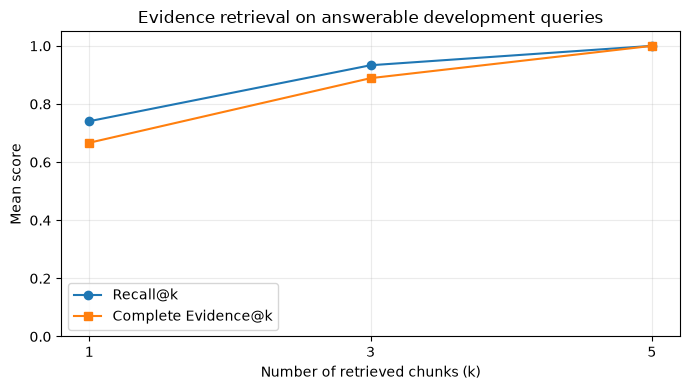

In [6]:
import matplotlib.pyplot as plt

k_values = [1, 3, 5]
overall_metrics = ranking_metrics["overall"]

recall_values = [overall_metrics[f"recall_at_{k}"] for k in k_values]
complete_values = [
    overall_metrics[f"complete_evidence_at_{k}"] for k in k_values
]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_values, recall_values, marker="o", label="Recall@k")
ax.plot(k_values, complete_values, marker="s", label="Complete Evidence@k")
ax.set(
    xlabel="Number of retrieved chunks (k)",
    ylabel="Mean score",
    title="Evidence retrieval on answerable development queries",
)
ax.set_xticks(k_values)
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

**Observation.** With `k=3`, mean Recall is about **0.933**, whereas Complete Evidence is about **0.889**. With `k=5`, both reach **1.0** on development. This does not establish that Top-5 leads to better generated answers: added context may also be distracting or costly.

### 2.3 Single-evidence vs. multi-evidence queries

Comparing Complete Evidence@k between categories helps identify whether retrieving all necessary chunks is especially difficult for questions that combine facts.

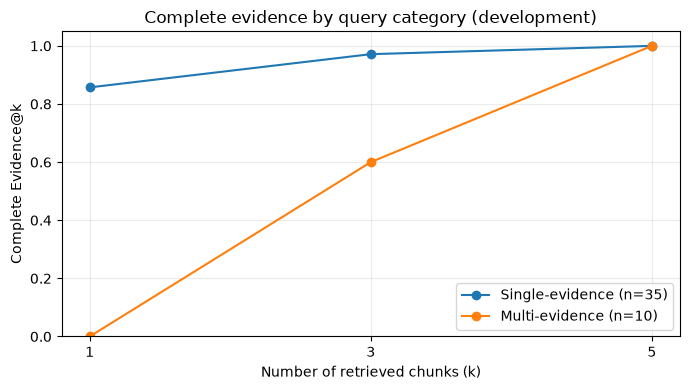

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))

for group, label in (
    ("single_evidence", "Single-evidence (n=35)"),
    ("multi_evidence", "Multi-evidence (n=10)"),
):
    values = [ranking_metrics[group][f"complete_evidence_at_{k}"] for k in k_values]
    ax.plot(k_values, values, marker="o", label=label)

ax.set(
    xlabel="Number of retrieved chunks (k)",
    ylabel="Complete Evidence@k",
    title="Complete evidence by query category (development)",
)
ax.set_xticks(k_values)
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

**Observation.** At `k=3`, Complete Evidence is **0.971** for single-evidence queries but **0.600** for multi-evidence queries. Complete Evidence@1 is **necessarily zero** for the multi-evidence group: no single retrieved chunk can contain two or more distinct annotated chunk IDs. This is a property of the metric and the task design, not an additional model failure.

### 2.4 Which questions are incomplete at Top-3?

The aggregate difference is driven by a small number of queries. Inspect which annotated chunks are missing among the first three results and at which rank they appear in the saved Top-5 list.

Computing these display-only columns does not change the evaluation metrics or the gold annotations.

In [8]:
query_metrics_df = pd.DataFrame(summary_data["query_metrics"])

incomplete_at_3 = query_metrics_df.loc[
    query_metrics_df["complete_evidence_at_3"] == 0
].copy()

incomplete_at_3["missing_at_3"] = [
    sorted(set(gold) - set(retrieved[:3]))
    for gold, retrieved in zip(
        incomplete_at_3["relevant_ids"],
        incomplete_at_3["retrieved_ids"],
    )
]

incomplete_at_3["missing_ranks"] = [
    {chunk_id: retrieved.index(chunk_id) + 1 for chunk_id in missing}
    for missing, retrieved in zip(
        incomplete_at_3["missing_at_3"],
        incomplete_at_3["retrieved_ids"],
    )
]

assert len(incomplete_at_3) == 5

incomplete_at_3[
    ["query_id", "category", "query", "missing_at_3", "missing_ranks"]
].reset_index(drop=True)

,query_id,category,query,missing_at_3,missing_ranks
0,q_010,multi_evidence,¿Qué mide un hemograma y para qué se utiliza?,[medlineplus_complete_blood_count_001],{'medlineplus_complete_blood_count_001': 4}
1,q_037,single_evidence,¿El golpe de calor es una urgencia médica y es...,[medlineplus_heat_illness_002],{'medlineplus_heat_illness_002': 5}
2,q_047,multi_evidence,¿Qué desencadenantes frecuentes se asocian a l...,[medlineplus_headache_001],{'medlineplus_headache_001': 4}
3,q_048,multi_evidence,¿Cuáles son las señales de golpe de calor y qu...,[medlineplus_heat_illness_002],{'medlineplus_heat_illness_002': 4}
4,q_049,multi_evidence,"En Demo Health Clinic, ¿con cuánto aviso se ca...",[demo_clinic_medical_records_policy_002],{'demo_clinic_medical_records_policy_002': 4}


**Interpretation.** The five incomplete Top-3 cases are **Q010, Q037, Q047, Q048, and Q049**. In all five, the missing annotated evidence appears at rank 4 or 5. Q047 is noteworthy: the first two retrieved chunks concern allergies rather than headaches. We will inspect these rankings in more detail in **Section 5 — Error analysis**.

**Provisional decision:** retain **Top-5** as the development-selected baseline because it recovers the full annotated evidence set for all 45 answerable development queries. This decision remains subject to end-to-end response evaluation; the held-out test split has not been examined.

## 3. Similarity score distributions

**Question:** Can the cosine similarity of the top-ranked chunk distinguish answerable questions from those with insufficient evidence?

For each development query, we analyze the score of the **first retrieved chunk** (`top1_score`). We compare three groups:

- **Answerable:** `single_evidence` + `multi_evidence` (45 queries).
- **In-domain unsupported:** related to the medical/clinic domain, but missing the requested facts (8 queries).
- **Out-of-domain:** unrelated to the knowledge base (7 queries).

A high similarity score indicates that the retriever finds a semantically related chunk. **It does not establish that the chunk contains all the facts required to answer the question.** These scores are not calibrated probabilities of answerability.

The small, intentionally balanced development set describes this benchmark only; it does not represent real user traffic.

### 3.1 Descriptive statistics

Compare the minimum, quartiles, median, and maximum Top-1 score for each group. Unlike the ranking metrics in Section 2, this analysis **includes unsupported questions**.

In [9]:
score_group_labels = {
    "single_evidence": "Answerable",
    "multi_evidence": "Answerable",
    "in_domain_unsupported": "In-domain unsupported",
    "out_of_domain": "Out-of-domain",
}
score_group_order = [
    "Answerable",
    "In-domain unsupported",
    "Out-of-domain",
]

score_df = queries_df.copy()
score_df["score_group"] = score_df["category"].map(score_group_labels)

assert score_df["score_group"].notna().all()

score_stats_df = (
    score_df.groupby("score_group")["top1_score"]
    .agg(
        n="size",
        minimum="min",
        q25=lambda values: values.quantile(0.25),
        median="median",
        q75=lambda values: values.quantile(0.75),
        maximum="max",
    )
    .reindex(score_group_order)
)

score_stats_df.round(3)

,n,minimum,q25,median,q75,maximum
score_group,,,,,,
Answerable,45,0.365,0.639,0.698,0.771,0.821
In-domain unsupported,8,0.358,0.413,0.503,0.537,0.583
Out-of-domain,7,0.094,0.132,0.165,0.200,0.425


**What to look for.** Out-of-domain queries generally have lower scores, whereas the in-domain unsupported group occupies part of the same score range as answerable queries. The quartiles summarize the observed sample and should not be interpreted as estimates with high precision, particularly for the unsupported groups (`n=8` and `n=7`).

### 3.2 Top-1 score histogram

The plot uses **density normalization** so groups with different sample sizes can be compared on the same axes. Each curve describes the distribution *within* its group; it does not show the prevalence of that group in real traffic.

With only 7–8 examples in the unsupported groups, histogram shapes are sensitive to bin width. We use this plot for an exploratory view, not for selecting an exact threshold.

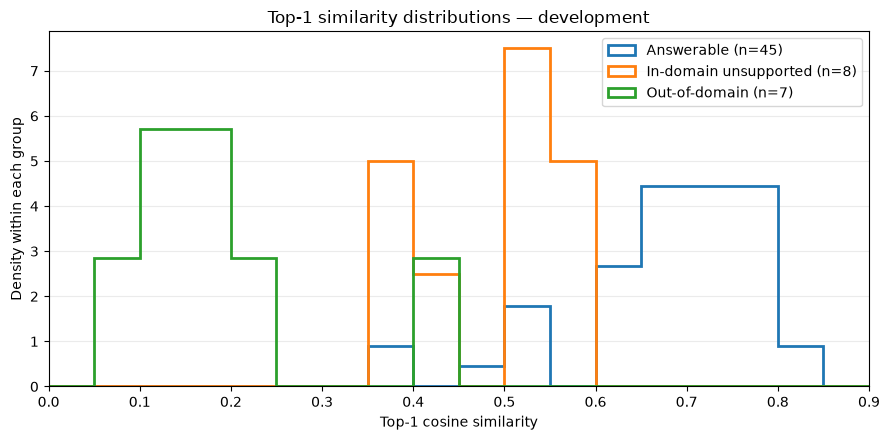

In [10]:
# Shared 0.05-wide bins cover every development Top-1 score.
bins = [index / 20 for index in range(19)]  # 0.00, 0.05, ..., 0.90

fig, ax = plt.subplots(figsize=(9, 4.5))

for group in score_group_order:
    values = score_df.loc[
        score_df["score_group"] == group, "top1_score"
    ]
    ax.hist(
        values,
        bins=bins,
        density=True,
        histtype="step",
        linewidth=2,
        label=f"{group} (n={len(values)})",
    )

ax.set(
    xlabel="Top-1 cosine similarity",
    ylabel="Density within each group",
    title="Top-1 similarity distributions — development",
)
ax.set_xlim(0, 0.9)
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

### 3.3 Boxplots with individual observations

A boxplot makes the relative medians, quartiles, and overlap easier to inspect. We overlay **every query score** because our dataset is small and summary statistics could hide important individual examples.

The point positions are offset deterministically along the vertical axis for readability; that offset carries no statistical meaning.

/tmp/ipykernel_18605/3121198322.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values_by_group, vert=False, showfliers=False)


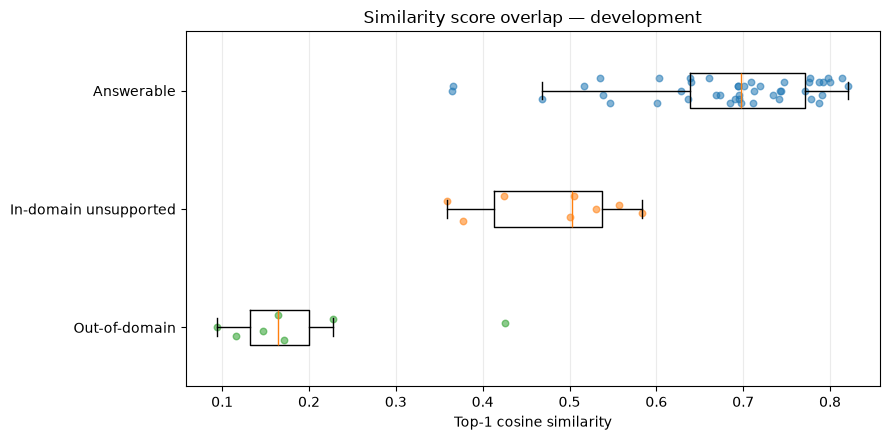

In [11]:
values_by_group = [
    score_df.loc[score_df["score_group"] == group, "top1_score"].tolist()
    for group in score_group_order
]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot(values_by_group, vert=False, showfliers=False)

for position, values in enumerate(values_by_group, start=1):
    vertical_positions = [
        position + ((index % 7) - 3) * 0.035
        for index in range(len(values))
    ]
    ax.scatter(values, vertical_positions, alpha=0.55, s=22)

ax.set_yticks(range(1, len(score_group_order) + 1), score_group_order)
ax.invert_yaxis()
ax.set(
    xlabel="Top-1 cosine similarity",
    title="Similarity score overlap — development",
)
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### 3.4 An overlap that no single threshold can resolve

To **accept** an answerable query, our current rule needs `top1_score >= threshold`. To **reject** an unsupported query, it needs `top1_score < threshold`.

Compare Q004 and Q052:

- **Q004:** asks about anaphylaxis, and its annotated evidence is retrieved in first position, but the Top-1 score is only about **0.365**.
- **Q052:** asks about the user's *personal* allergies; only general allergy information is available, yet its Top-1 score is about **0.583**.

A threshold low enough to accept Q004 will also accept Q052. A threshold high enough to reject Q052 will reject Q004. This is a **counterexample to perfect answerability separation using a single Top-1 score threshold** on development.

In [12]:
case_ids = ["q_004", "q_052", "q_056"]

score_cases_df = (
    score_df.set_index("query_id")
    .loc[
        case_ids,
        ["query", "score_group", "top1_score", "top1_chunk_id"],
    ]
    .reset_index()
)

score_cases_df.round({"top1_score": 3})

,query_id,query,score_group,top1_score,top1_chunk_id
0,q_004,¿Qué es la anafilaxia y qué tipo de atención r...,Answerable,0.365,medlineplus_allergy_001
1,q_052,"Según mi historia clínica, ¿a qué sustancias s...",In-domain unsupported,0.583,medlineplus_allergy_000
2,q_056,¿Cómo reservo una mesa en un restaurante para ...,Out-of-domain,0.425,demo_clinic_appointment_policy_002


In [13]:
lowest_answerable = score_df.loc[
    score_df["score_group"] == "Answerable", "top1_score"
].min()
highest_in_domain_unsupported = score_df.loc[
    score_df["score_group"] == "In-domain unsupported", "top1_score"
].max()

assert lowest_answerable < highest_in_domain_unsupported

print(f"Lowest answerable Top-1 score: {lowest_answerable:.3f}")
print(
    "Highest in-domain unsupported Top-1 score: "
    f"{highest_in_domain_unsupported:.3f}"
)
print("The two observed score ranges overlap: perfect threshold separation is impossible.")

Lowest answerable Top-1 score: 0.365
Highest in-domain unsupported Top-1 score: 0.583
The two observed score ranges overlap: perfect threshold separation is impossible.


**Interpretation.** Similarity is useful for identifying candidate evidence, but cannot certify evidence sufficiency. The clearest failure mode is *in-domain unsupported*: the retrieved documents share the question's topic without containing the requested patient-specific or real-time information. Q056 (restaurant booking) additionally illustrates that an out-of-domain request can resemble an in-domain administrative task.

**Limitations:** These are only 60 development examples, with 15 unsupported queries. The groups were constructed for evaluation and do not reflect real-world frequencies. No model predictions from the held-out test split have been accessed.

**Next:** In Section 4, quantify the retrieve-or-reject trade-off using the already-saved confusion matrices across candidate thresholds. This exploratory overlap analysis does **not** select a new threshold.

## 4. Retrieve-or-reject analysis

**Question:** What happens when a single threshold on the highest cosine similarity score is used to decide whether to return retrieved evidence?

The current `SemanticRetriever.retrieve()` accepts a query when `top1_score >= threshold`, and otherwise returns no chunks. Here, **positive means answerable from the KB**, not “medically safe” or “correctly answered by an LLM.” The annotations supply that answerability label; the threshold supplies the predicted decision.

We use the precomputed evaluation (`retrieval_threshold_dev_v2.json`) rather than rerunning MiniLM or re-implementing the tested acceptance metrics.

- **Sensitivity / TPR** = TP / (TP + FN): fraction of answerable queries accepted.
- **Specificity / TNR** = TN / (TN + FP): fraction of unsupported queries rejected.
- **False acceptance rate / FPR** = FP / (FP + TN): fraction of unsupported queries incorrectly accepted.
- **False rejection rate / FNR** = FN / (FN + TP): fraction of answerable queries incorrectly rejected.

These are **retrieval-gate decisions**, not actual LLM response outcomes. A query passing the gate can still produce an abstention or an unsupported answer downstream.

### 4.1 Decision metrics across candidate thresholds

The analysis includes six **development-only** thresholds. It is meant to characterize the trade-off, not to search indefinitely for the best-fitting decimal value on just 15 unsupported examples.

In [14]:
threshold_df = pd.DataFrame(threshold_data["threshold_results"]).sort_values("threshold")

assert (threshold_df["tp"] + threshold_df["fn"] == 45).all()
assert (threshold_df["tn"] + threshold_df["fp"] == 15).all()
assert (threshold_df["sensitivity"] + threshold_df["false_rejection_rate"] - 1).abs().max() < 1e-12
assert (threshold_df["specificity"] + threshold_df["false_acceptance_rate"] - 1).abs().max() < 1e-12

threshold_df[
    ["threshold", "tp", "fn", "tn", "fp", "sensitivity", "specificity", "false_acceptance_rate", "false_rejection_rate"]
].round(3).reset_index(drop=True)

,threshold,tp,fn,tn,fp,sensitivity,specificity,false_acceptance_rate,false_rejection_rate
0,0.30,45,0,6,9,1.000,0.400,0.600,0.000
1,0.40,43,2,8,7,0.956,0.533,0.467,0.044
2,0.45,43,2,10,5,0.956,0.667,0.333,0.044
3,0.50,42,3,10,5,0.933,0.667,0.333,0.067
4,0.55,38,7,13,2,0.844,0.867,0.133,0.156
5,0.60,38,7,15,0,0.844,1.000,0.000,0.156


### 4.2 Sensitivity–specificity trade-off

An ideal gate would accept every supported question and reject every unsupported question. In practice, increasing the threshold trades sensitivity for specificity. The plot highlights the **current baseline threshold (0.30)**; other candidates are diagnostic comparisons, not test results.

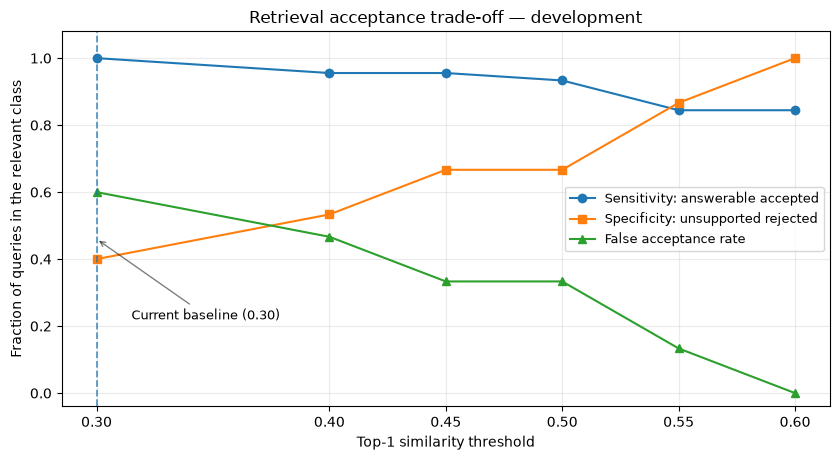

In [15]:
fig, ax = plt.subplots(figsize=(8.5, 4.7))

for metric_name, label, marker in (
    ("sensitivity", "Sensitivity: answerable accepted", "o"),
    ("specificity", "Specificity: unsupported rejected", "s"),
    ("false_acceptance_rate", "False acceptance rate", "^"),
):
    ax.plot(threshold_df["threshold"], threshold_df[metric_name], marker=marker, label=label)

ax.axvline(0.30, linestyle="--", linewidth=1.3, alpha=0.75)
ax.annotate("Current baseline (0.30)", xy=(0.30, 0.46), xytext=(0.315, 0.22),
            arrowprops={"arrowstyle": "->", "alpha": 0.5}, fontsize=9)
ax.set(
    xlabel="Top-1 similarity threshold",
    ylabel="Fraction of queries in the relevant class",
    title="Retrieval acceptance trade-off — development",
)
ax.set_xticks(threshold_df["threshold"])
ax.set_ylim(-0.04, 1.08)
ax.grid(alpha=0.25)
ax.legend(loc="center right", fontsize=9)
plt.tight_layout()
plt.show()

**Interpretation.** At `t=0.30`, all 45 answerable development questions pass the gate (**100% sensitivity**), but **9 of 15 unsupported** questions also pass (**60% false acceptance**). At `t=0.60`, development has zero false acceptances, but **7 of 45 answerable** questions are rejected. This is a meaningful trade-off, not an argument that either threshold generalizes perfectly. The candidate `t=0.50` is dominated by `t=0.45`: both have five false acceptances, but 0.50 rejects one additional answerable question.

### 4.3 Confusion matrix at the current threshold

Rows show **ground-truth answerability** and columns show the **retrieval-gate decision**. Counts are shown rather than only accuracy because our development dataset has intentionally more answerable than unsupported questions (45 vs. 15).

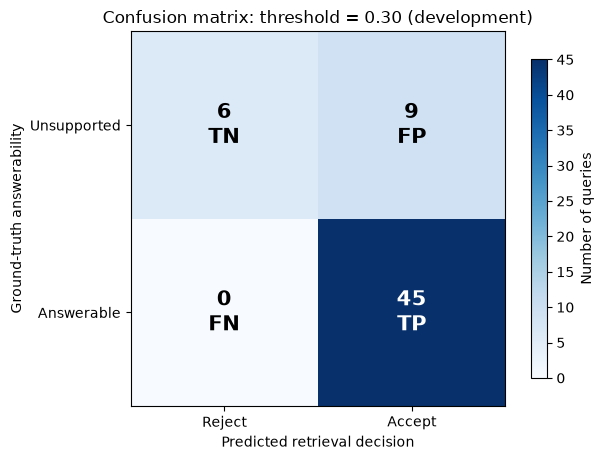

In [16]:
import numpy as np

baseline = threshold_df.loc[threshold_df["threshold"].eq(0.30)].iloc[0]
# Rows = actual Unsupported, Answerable; columns = predicted Reject, Accept.
confusion = np.array(
    [
        [int(baseline["tn"]), int(baseline["fp"])],
        [int(baseline["fn"]), int(baseline["tp"])],
    ]
)
assert confusion.tolist() == [[6, 9], [0, 45]]

fig, ax = plt.subplots(figsize=(6.3, 4.7))
heatmap = ax.imshow(confusion, cmap="Blues", vmin=0, vmax=45)

for row in range(2):
    for col in range(2):
        count = confusion[row, col]
        label = (("TN", "FP"), ("FN", "TP"))[row][col]
        ax.text(col, row, f"{count}\n{label}", ha="center", va="center",
                color="white" if count > 22 else "black", fontsize=15, fontweight="bold")

ax.set_xticks([0, 1], ["Reject", "Accept"])
ax.set_yticks([0, 1], ["Unsupported", "Answerable"])
ax.set(xlabel="Predicted retrieval decision", ylabel="Ground-truth answerability",
       title="Confusion matrix: threshold = 0.30 (development)")
fig.colorbar(heatmap, ax=ax, label="Number of queries", shrink=0.85)
plt.tight_layout()
plt.show()

**Reading the matrix.** The diagonal contains correct gate decisions (6 true negatives, 45 true positives). The **9 false positives** are unsupported queries for which the retriever nevertheless returns context; this does **not** mean it has already generated 9 hallucinated answers. That downstream risk must be evaluated separately.

### 4.4 Which unsupported categories pass the gate?

Aggregating all unsupported queries hides a crucial distinction. Queries unrelated to the KB can be easy to reject, whereas in-domain questions may retrieve strongly related **but incomplete** evidence. We compute a **display-only breakdown** from the stored Top-1 scores, using the same `>=` decision rule as `retrieve()`.

In [17]:
category_gate_rows = []
for threshold in (0.30, 0.45, 0.60):
    for category in ("in_domain_unsupported", "out_of_domain"):
        rows = queries_df.loc[queries_df["category"] == category]
        accepted = int((rows["top1_score"] >= threshold).sum())
        category_gate_rows.append(
            {"threshold": threshold, "category": category,
             "accepted_unsupported": accepted, "n_queries": len(rows),
             "false_acceptance_rate": accepted / len(rows)}
        )

category_gate_df = pd.DataFrame(category_gate_rows)
# Cross-check category totals against the independently generated threshold report.
for threshold in (0.30, 0.45, 0.60):
    from_categories = category_gate_df.loc[
        category_gate_df["threshold"] == threshold, "accepted_unsupported"
    ].sum()
    from_report = threshold_df.loc[threshold_df["threshold"] == threshold, "fp"].iloc[0]
    assert from_categories == from_report

category_gate_df.round(3)

,threshold,category,accepted_unsupported,n_queries,false_acceptance_rate
0,0.30,in_domain_unsupported,8,8,1.000
1,0.30,out_of_domain,1,7,0.143
2,0.45,in_domain_unsupported,5,8,0.625
3,0.45,out_of_domain,0,7,0.000
4,0.60,in_domain_unsupported,0,8,0.000
5,0.60,out_of_domain,0,7,0.000


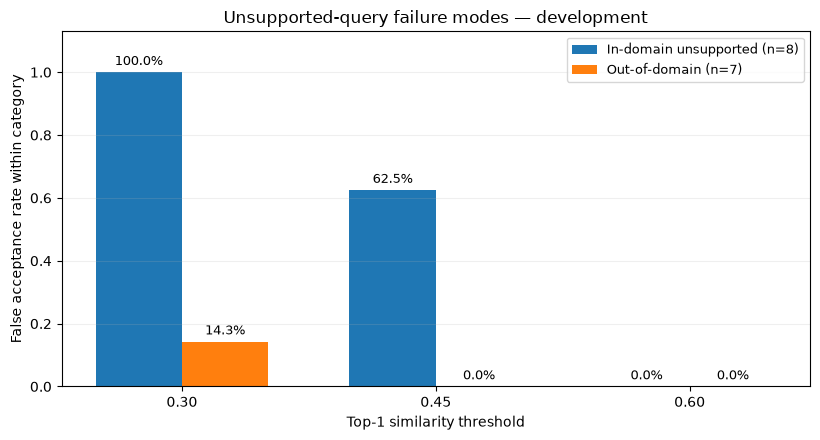

In [18]:
fig, ax = plt.subplots(figsize=(8.3, 4.5))
threshold_values = [0.30, 0.45, 0.60]
x = np.arange(len(threshold_values))
bar_width = 0.34

for i, (category, label) in enumerate((
    ("in_domain_unsupported", "In-domain unsupported (n=8)"),
    ("out_of_domain", "Out-of-domain (n=7)"),
)):
    values = [
        category_gate_df.loc[
            category_gate_df["threshold"].eq(t) & category_gate_df["category"].eq(category),
            "false_acceptance_rate",
        ].iloc[0]
        for t in threshold_values
    ]
    bars = ax.bar(x + (i - 0.5) * bar_width, values, width=bar_width, label=label)
    ax.bar_label(bars, labels=[f"{value:.1%}" for value in values], padding=3, fontsize=9)

ax.set_xticks(x, [f"{t:.2f}" for t in threshold_values])
ax.set(
    xlabel="Top-1 similarity threshold",
    ylabel="False acceptance rate within category",
    title="Unsupported-query failure modes — development",
)
ax.set_ylim(0, 1.13)
ax.grid(axis="y", alpha=0.2)
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

**Interpretation.** At `t=0.30`, **all eight in-domain unsupported** questions are accepted, while only one of seven out-of-domain questions is accepted. Even at `t=0.45`, **five of eight in-domain unsupported** examples pass the gate. The main weakness is therefore not merely filtering unrelated topics: it is distinguishing *related evidence* from *sufficient evidence*.

**Selection caveat:** None of these thresholds is a calibrated probability cutoff. A zero false-acceptance rate on eight in-domain examples (at 0.60) would be especially fragile evidence for safety.

## 5. Qualitative error analysis

**Question:** What do the failures look like, and which downstream components would need to address them?

The overall ranking metrics can conceal different error modes. The following case studies inspect **saved retrieval rankings**. They are examples, not a prevalence estimate.

We distinguish:

1. **Ranking error:** necessary evidence exists, but is placed too low in the results.
2. **Evidence sufficiency failure:** a highly related chunk does **not** contain the requested fact.
3. **Threshold false rejection:** usable evidence is found, but its score is below a stricter gate.

In each case we inspect the *annotated evidence IDs*. We do not adjust gold annotations to make the retrieved ranking look better.

### 5.1 Ranking case study — Q047: headache vs. allergy

Q047 asks about common headache triggers and warning signs. The two annotated headache chunks are present in Top-5, but the first two ranked chunks concern allergies. Thus **Top-3 misses one required chunk** even though the topic is medically related.

In [19]:
def show_retrieval_case(query_id: str) -> pd.DataFrame:
    """Display the saved ranking and marked gold evidence for one query."""
    matches = [item for item in results if item["query_id"] == query_id]
    if len(matches) != 1:
        raise ValueError(f"Expected exactly one query named {query_id}")
    item = matches[0]
    gold = set(item["relevant_chunk_ids"])
    return pd.DataFrame(
        [
            {
                "rank": hit["rank"],
                "chunk_id": hit["chunk_id"],
                "score": hit["score"],
                "annotated_evidence": "YES" if hit["chunk_id"] in gold else "no",
            }
            for hit in item["retrieved_chunks"]
        ]
    ).round({"score": 3})

q047 = queries_df.loc[queries_df["query_id"].eq("q_047")].iloc[0]
print("Q047:", q047["query"])
show_retrieval_case("q_047")

Q047: ¿Qué desencadenantes frecuentes se asocian a la cefalea y cuáles son sus señales de alarma?


,rank,chunk_id,score,annotated_evidence
0,1,medlineplus_allergy_001,0.535,no
1,2,medlineplus_allergy_000,0.507,no
2,3,medlineplus_headache_002,0.479,YES
3,4,medlineplus_headache_001,0.464,YES
4,5,medlineplus_dehydration_002,0.433,no


### 5.2 Multi-evidence case study — Q049: mixing clinic policies

Q049 combines the fictional clinic's appointment cancellation policy with its medical-record processing target. The two answers reside in **different policy documents**. The second required chunk is ranked fourth, below related but insufficient material about laboratory reports and appointments.

This highlights why a good Top-1 ranking alone cannot measure complete evidence retrieval.

In [20]:
q049 = queries_df.loc[queries_df["query_id"].eq("q_049")].iloc[0]
print("Q049:", q049["query"])
show_retrieval_case("q_049")

Q049: En Demo Health Clinic, ¿con cuánto aviso se cancela un turno y cuánto lleva procesar una solicitud verificada de historia clínica?


,rank,chunk_id,score,annotated_evidence
0,1,demo_clinic_appointment_policy_001,0.694,YES
1,2,demo_clinic_laboratory_results_policy_001,0.693,no
2,3,demo_clinic_appointment_policy_000,0.687,no
3,4,demo_clinic_medical_records_policy_002,0.588,YES
4,5,demo_clinic_medical_records_policy_000,0.566,no


### 5.3 High-similarity but unsupported — Q052: personal allergies

Q052 asks for the user's **personal allergies from their medical record**. The KB describes allergies generally, but contains no patient-specific records. The first chunk is therefore **topically relevant but not sufficient**. This is not a gold-ranking error: unsupported queries deliberately have an empty relevant evidence set.

In [21]:
q052 = queries_df.loc[queries_df["query_id"].eq("q_052")].iloc[0]
print("Q052:", q052["query"])
print(f"Gold answerable label: {q052['answerable']}")
print(f"Top-1 score: {q052['top1_score']:.3f}")
print(f"Gate at t=0.30: {'ACCEPT' if q052['top1_score'] >= 0.30 else 'REJECT'}")
show_retrieval_case("q_052")

Q052: Según mi historia clínica, ¿a qué sustancias soy alérgico?
Gold answerable label: False
Top-1 score: 0.583
Gate at t=0.30: ACCEPT


,rank,chunk_id,score,annotated_evidence
0,1,medlineplus_allergy_000,0.583,no
1,2,medlineplus_allergy_001,0.546,no
2,3,medlineplus_allergy_002,0.476,no
3,4,medlineplus_common_cold_003,0.359,no
4,5,medlineplus_common_cold_001,0.318,no


### 5.4 Low similarity but valid evidence — Q004: anaphylaxis

Q004 asks a **general** medical-information question about anaphylaxis. Its gold chunk appears in first position, yet the score is around 0.365. At a threshold of 0.45 it would be **falsely rejected**, despite successful ranking. The example counters the assumption that a low score always means evidence is missing.

In [22]:
q004 = queries_df.loc[queries_df["query_id"].eq("q_004")].iloc[0]
print("Q004:", q004["query"])
print(f"Top-1 score: {q004['top1_score']:.3f}")
print(f"Gate at t=0.30: {'ACCEPT' if q004['top1_score'] >= 0.30 else 'REJECT'}")
print(f"Gate at t=0.45: {'ACCEPT' if q004['top1_score'] >= 0.45 else 'REJECT'}")
show_retrieval_case("q_004")

Q004: ¿Qué es la anafilaxia y qué tipo de atención requiere?
Top-1 score: 0.365
Gate at t=0.30: ACCEPT
Gate at t=0.45: REJECT


,rank,chunk_id,score,annotated_evidence
0,1,medlineplus_allergy_001,0.365,YES
1,2,medlineplus_allergy_000,0.302,no
2,3,medlineplus_diarrhea_002,0.297,no
3,4,medlineplus_sore_throat_002,0.276,no
4,5,medlineplus_dehydration_000,0.272,no


### 5.5 False acceptances and false rejections: full audit lists

Instead of showing only cherry-picked examples, inspect **all** mistakes made by the current gate and all newly introduced false rejections at a stricter threshold. This helps distinguish representative failure modes from anecdotes.

In [23]:
baseline_errors = queries_df.loc[
    (~queries_df["answerable"]) & (queries_df["top1_score"] >= 0.30),
    ["query_id", "category", "query", "top1_score", "top1_chunk_id"],
].sort_values("top1_score", ascending=False)

assert len(baseline_errors) == int(baseline["fp"]) == 9
baseline_errors.round({"top1_score": 3}).reset_index(drop=True)

,query_id,category,query,top1_score,top1_chunk_id
0,q_052,in_domain_unsupported,"Según mi historia clínica, ¿a qué sustancias s...",0.583,medlineplus_allergy_000
1,q_050,in_domain_unsupported,¿Cuál es el número de teléfono real para pedir...,0.556,demo_clinic_appointment_policy_000
2,q_051,in_domain_unsupported,¿Hay turnos libres este sábado por la mañana e...,0.531,demo_clinic_appointment_policy_000
3,q_055,in_domain_unsupported,¿Ya está listo en este momento el cultivo de g...,0.505,medlineplus_strep_a_test_002
4,q_053,in_domain_unsupported,¿Qué valor de hemoglobina me dio el análisis q...,0.500,medlineplus_complete_blood_count_003
5,q_056,out_of_domain,¿Cómo reservo una mesa en un restaurante para ...,0.425,demo_clinic_appointment_policy_002
6,q_012,in_domain_unsupported,¿Cuánto cuesta hacerse un hemograma en Demo He...,0.425,medlineplus_complete_blood_count_002
7,q_054,in_domain_unsupported,¿Qué dosis exacta de paracetamol corresponde d...,0.377,medlineplus_sore_throat_002
8,q_013,in_domain_unsupported,¿Cuál es mi nivel de sodio según mis últimos a...,0.358,medlineplus_complete_blood_count_003


In [24]:
strict_threshold = 0.60
false_rejected = queries_df.loc[
    queries_df["answerable"] & (queries_df["top1_score"] < strict_threshold),
    ["query_id", "category", "query", "top1_score", "top1_chunk_id", "relevant_ids"],
].sort_values("top1_score")

assert len(false_rejected) == int(
    threshold_df.loc[threshold_df["threshold"].eq(strict_threshold), "fn"].iloc[0]
) == 7
false_rejected.round({"top1_score": 3}).reset_index(drop=True)

,query_id,category,query,top1_score,top1_chunk_id,relevant_ids
0,q_004,single_evidence,¿Qué es la anafilaxia y qué tipo de atención r...,0.365,medlineplus_allergy_001,[medlineplus_allergy_001]
1,q_003,single_evidence,¿Tengo que estar en ayunas para hacerme un hem...,0.365,medlineplus_complete_blood_count_002,[medlineplus_complete_blood_count_002]
2,q_024,single_evidence,¿Un resultado anormal del hemograma alcanza po...,0.468,medlineplus_complete_blood_count_003,[medlineplus_complete_blood_count_003]
3,q_010,multi_evidence,¿Qué mide un hemograma y para qué se utiliza?,0.516,medlineplus_complete_blood_count_000,"[medlineplus_complete_blood_count_000, medline..."
4,q_047,multi_evidence,¿Qué desencadenantes frecuentes se asocian a l...,0.535,medlineplus_allergy_001,"[medlineplus_headache_001, medlineplus_headach..."
5,q_023,single_evidence,¿Qué tipos de células y otras mediciones apare...,0.539,medlineplus_complete_blood_count_000,[medlineplus_complete_blood_count_000]
6,q_007,single_evidence,¿Tengo que verificar mi identidad para solicit...,0.547,demo_clinic_medical_records_policy_001,[demo_clinic_medical_records_policy_001]


**Error-analysis synthesis.** The main failures are not interchangeable:

- **Rank displacement** (Q047, Q049) argues for studying retrieval depth, ranking representations, or reranking.
- **Unsupported yet related** (Q052) argues for a **separate evidence-sufficiency check** before generating an answer.
- **Low score on correct evidence** (Q004) argues against treating cosine similarity as a sufficient answerability classifier.

We should not relabel Q047/Q052 or fine-tune the gate based on selected examples and then report those same development examples as independent performance evidence.

## 6. Development conclusions and next steps

### 6.1 What the development benchmark supports

This is a **small, manually annotated, educational** benchmark: 60 development queries, including 45 answerable and 15 unsupported, against a fixed 54-chunk KB.

**Ranking:** Top-5 includes *all annotated required evidence* for all 45 answerable development questions (**Complete Evidence@5 = 1.0**). Top-3 includes complete evidence for 40/45 (**0.889**), and for 6/10 multi-evidence cases (**0.600**).

**Acceptance:** At the baseline Top-1 threshold of 0.30, the retrieval gate accepts 45/45 answerable questions but also accepts 9/15 unsupported questions (**FPR = 0.60**). In-domain unsupported queries are particularly hard for a similarity-only gate: all 8 pass at this threshold.

**Qualitative finding:** Similarity and evidence sufficiency are separate problems; a high score can be associated with missing patient-specific or live information, and a low score can still accompany correctly retrieved evidence.

These observations are about retrieval against one annotated evidence set. They do not measure LLM answer quality, citation faithfulness, clinical reliability, or deployment safety.

### 6.2 Provisional baseline choices from development

| Component | Development-selected setting | Justification |
| --- | --- | --- |
| Knowledge base | KB v2: 15 documents / 54 section chunks | Fixed, annotated source corpus |
| Embedding model | `paraphrase-multilingual-MiniLM-L12-v2` | Existing multilingual pretrained baseline; **not fine-tuned** |
| Embedding input | Title + section + content | Current implementation of `SemanticRetriever` |
| Retrieval ranking | Cosine similarity | Existing semantic-search behavior |
| **Retrieval depth** | **Top-5** | Complete Evidence@5 = 45/45 on development, compared with 40/45 at Top-3 |
| **Preliminary similarity filter** | **Top-1 score >= 0.30** | Retains all answerable development questions; **not** a reliability or answerability guarantee |
| Evidence sufficiency | **Not implemented yet** | Needed to study abstention for in-domain unsupported requests |

**Important implementation gap:** `run_retrieval_benchmark.py` evaluated `search(..., top_k=5)`, while `SemanticRetriever.retrieve()` currently defaults to **`top_k=3`**. The table records the **development-selected experimental configuration**, not an assertion that the application already uses Top-5 everywhere. Before end-to-end evaluation, the caller must explicitly request Top-5 or the application configuration must be changed and tested.

The reason to **retain 0.30 provisionally** is to avoid rejecting answerable questions at the initial retrieval gate, **not** because 0.30 provides satisfactory protection against unsupported queries. This design explicitly depends on later, separately measured evidence-sufficiency behavior.

### 6.3 Experimental limitations

1. **Small and curated dataset.** Only 15 unsupported development questions (8 in-domain, 7 out-of-domain) make error rates noisy. The category proportions do not match realistic traffic.
2. **Same corpus across splits.** The future held-out test set contains unseen question wordings but overlaps in underlying documents, topics and some information needs. It is not document-disjoint or clinically representative.
3. **Gold evidence is one annotated set per question.** Other sufficient evidence sets might exist; Complete Evidence@k judges retrieval against the recorded IDs only.
4. **Synthetic/fictitious administrative content.** Demo clinic policies are not real operational guarantees.
5. **No response-level validation.** Retrieving annotated evidence is a prerequisite but does not prove that the LLM will use it faithfully. The threshold experiment measures a gate decision, not generated hallucinations.
6. **Reproducibility metadata is incomplete.** The outputs record the model name, but not its exact downloaded revision, all dependency versions or a complete content fingerprint. Record these before a strict reproducibility claim.

The system is a **research/educational prototype, not a medical device** or clinically validated advisor.

### 6.4 Hold-out protocol: do not tune on test

**Next steps, in order:**

1. Review and edit the interpretation in this notebook; decide what claims you are comfortable defending.
2. Update `RETRIEVAL_BENCHMARK_PROTOCOL_V2.md` with the chosen configuration, supporting development metrics, dataset/corpus snapshot and known limitations. Fix its outdated `_reviewed.json` file references.
3. Freeze model, KB content, embedding representation, Top-k, threshold and evaluation rules **before running test**. Where possible, store repository commit, corpus hash and exact embedding model revision.
4. Run **test once** with the frozen ranking configuration. Summarize its 45 answerable questions, and evaluate acceptance at the *preselected 0.30 threshold* without choosing a new test-optimal value.
5. Report test results descriptively as held-out question performance for this known corpus. If test exposes new issues, do not retroactively tune and quote the same test as an independent estimate; use a future new holdout if further optimization is necessary.
6. For the next class, evaluate **grounded generation, abstention, and faithfulness** separately from retrieval ranking.

**Takeaway:** A semantic retriever can be excellent at collecting candidate context and still be unreliable at deciding whether that context answers the question. The benchmark exposes this limitation rather than masking it with a single aggregate accuracy number.

---

### Reproducibility notes

Development artifacts consumed here:

- `retrieval_results_dev_v2.json` (all 60 ranked Top-5 lists and scores)
- `retrieval_summary_dev_v2.json` (ranking metrics on answerable questions)
- `retrieval_threshold_dev_v2.json` (retrieval-gate metrics on all 60 questions)

Generation commands (from the project root):

```bash
python -m evaluation.run_retrieval_benchmark --dataset dev
python -m evaluation.summarize_retrieval_results --dataset dev
python -m evaluation.evaluate_retrieval_threshold
```

**Notebook dependencies:** `pandas`, `numpy`, `matplotlib`, and Jupyter/IPython. They are analysis dependencies, not requirements for the production chatbot.

**Review status:** Development conclusions are subject to author review. The held-out test split remains unused. **Do not treat this notebook as a final-test report.**